# 04 · Double-lined binaries with TODCOR

**What you'll learn**

- why one template is not enough when two stars' spectra are blended
- how a TODCOR fit is built from the `todcor` atoms, one order and one pass at a time
- how to read the (v1, v2) maps, the amplitudes and the Cramér-Rao errors, over a whole orbit
- why short windows do not bias the fit, and when each order needs its own light ratio

Every step is a function call on plain arrays; the last cell checks that SPARTA's objects give
the same numbers. What the code computes is stated in
[correlation engines § TODCOR](../../docs/correlation_engines.md#todcor-ccf2d); *why* it works is derived in the deep dives
[`01_method`](../howto/todcor_detailed/01_method.ipynb), [`02_single_window_fit`](../howto/todcor_detailed/02_single_window_fit.ipynb)
and [`03_multiwindow_combination`](../howto/todcor_detailed/03_multiwindow_combination.ipynb).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta.instruments import Simulation
from sparta.instruments.simulated import component_spectra, simulate
from sparta.plotting import (DLNL_LABEL, GREY, apply_style, map_colorbar, map_image, mark_fit,
                             mark_truth, plot_data, plot_extra, plot_model, plot_points)
from sparta.preprocess import native_phases, resample_to_log_grid, resampling_noise_psd
# The TODCOR atoms (todcor) and the one-template CCF atom (unicor)
from todcor import joint_fit, model_flux, prepare_window, window_noise, window_stats
from unicor import C_KMS, ccf_order, dv_from_wave, extend_log_grid

# Use the SPARTA figure style
apply_style()

## 1. A simulated double-lined binary

Two PHOENIX stars, a 5800 K primary and a 4900 K secondary, on a circular 4.3-day orbit,
observed "like HARPS" in two 200 Å orders at signal-to-noise 50 per native pixel. Each star's
`amplitude` is its line dilution: the composite spectrum is
$1 + a_1\,(f_1 - 1) + a_2\,(f_2 - 1)$, so the primary gives roughly 70% of the light.

`simulate` returns one record per epoch: `rec.wave[o]`, `rec.flux[o]` for order `o`, on native
pixels (Å, air). `component_spectra` returns each star's noiseless rest-frame model,
`[star][order] -> (wave, flux)`: the two matched templates.

In [2]:
# Circular orbit: the stars move in antiphase around the systemic velocity gamma
P, K1, K2, gamma = 4.3, 45.0, 75.0, 10.0                 # days, km/s, km/s, km/s
# 12 random epochs over 20 d, and each star's true RV at each epoch
times = np.sort(np.random.default_rng(3).uniform(0, 20, 12))
v1_true = gamma + K1 * np.sin(2 * np.pi * times / P)
v2_true = gamma - K2 * np.sin(2 * np.pi * times / P)

# The two PHOENIX stars; amplitude is each star's share of the light
stars = [dict(teff=5800, logg=3.5, feh=0.5, vsini=4.0, amplitude=0.7),
         dict(teff=4900, logg=4.5, vsini=2.0, amplitude=0.3)]
# Describe the observation: HARPS-like, two 200 Å orders, S/N 50 per pixel
sim = Simulation(like="HARPS", windows_A=[(5000, 5200), (5300, 5500)], times=times,
                 rv_kms=np.column_stack([v1_true, v2_true]), components=stars,
                 snr=50, noise="constant", seed=4)
# Simulate the spectra and keep the injected truth
records, truth = simulate(sim)
# The two stars' clean templates, at rest
primary, secondary = component_spectra(sim)              # each: [order] -> (wave, flux), at rest
# Report what was simulated
print(f"{len(records)} epochs of {len(records[0].wave)} orders, native pixel "
      f"{dv_from_wave(records[0].wave[0]):.3f} km/s; amplitudes injected: {truth.amplitudes}")

12 epochs of 2 orders, native pixel 0.609 km/s; amplitudes injected: [0.7 0.3]


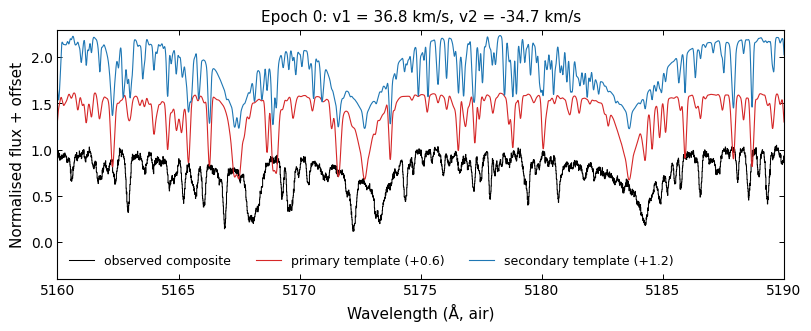

In [3]:
# Epoch 0: the observed blend, with the two stars' templates offset above it
k = 0
fig, ax = plt.subplots()
plot_data(ax, records[k].wave[0], records[k].flux[0], label="observed composite")
plot_model(ax, primary[0][0], primary[0][1] + 0.6, lw=0.8, label="primary template (+0.6)")
plot_extra(ax, secondary[0][0], secondary[0][1] + 1.2, lw=0.8, label="secondary template (+1.2)")
ax.set_xlim(5160, 5190)
ax.set_ylim(-0.4, 2.3)
ax.set_xlabel("Wavelength (Å, air)")
ax.set_ylabel("Normalised flux + offset")
ax.set_title(f"Epoch {k}: v1 = {v1_true[k]:.1f} km/s, v2 = {v2_true[k]:.1f} km/s")
ax.legend(loc="lower left", ncols=3)
plt.show()

## 2. Why one template is not enough

With only the primary's template, a one-dimensional CCF (notebook 03; here UNICOR's per-order
atom `ccf_order`, on a 0.3 km/s log-λ grid, ±120 km/s) lets the secondary's lines leak into the
correlation and pull the primary's peak. The pull is worst when the two stars' lines overlap:

In [4]:
DV = 0.3                                                  # km/s, the log-λ step of every fit below
# Fit the three most blended epochs with the primary's template alone
for n, k in enumerate(np.argsort(np.abs(v1_true - v2_true))[:3]):
    wave, flux = records[k].wave[0], records[k].flux[0]
    # One-template CCF of the order (unicor.ccf_order), on the log-λ grid, ±120 km/s
    one = ccf_order(*resample_to_log_grid(wave, flux, DV), *primary[0], 400, dv_kms=DV,
                    native_step_kms=dv_from_wave(wave), errors=True)
    # The error of the primary's RV against the injected truth
    bias = one.rv - v1_true[k]
    print(f"v1 - v2 = {v1_true[k] - v2_true[k]:6.1f} km/s:  one-template primary RV off by "
          f"{bias * 1e3:7.1f} m/s (reported error {one.erv * 1e3:.1f} m/s)")
    # The most blended epoch must show a gross bias, far above the reported error
    if n == 0:
        assert abs(bias) > 5 * one.erv                   # the most blended epoch: a gross bias

v1 - v2 =   11.0 km/s:  one-template primary RV off by  -266.2 m/s (reported error 17.1 m/s)
v1 - v2 =  -21.5 km/s:  one-template primary RV off by    45.1 m/s (reported error 17.3 m/s)
v1 - v2 =   45.7 km/s:  one-template primary RV off by   -46.0 m/s (reported error 17.5 m/s)


## 3. One epoch, step by step

TODCOR (Zucker & Mazeh 1994) models the spectrum as *both* templates, shifted to $v_1$ and $v_2$
and scaled by $a_1$ and $a_2$. The amplitudes enter linearly and are solved exactly at every
trial $(v_1, v_2)$, leaving a map over the two velocities. Each order is one *window*; we follow
epoch 0.

**Step 1: a log-λ grid.** There a Doppler shift is a translation (notebook 02), which TODCOR
applies as a Fourier phase factor. `resample_to_log_grid` puts the order on a 0.3 km/s grid,
finer than the native pixels.

In [5]:
# Epoch 0, first order
k, o = 0, 0
wave, flux = records[k].wave[o], records[k].flux[o]
native = dv_from_wave(wave)                               # km/s per native pixel
# Step 1: resample onto a log-λ grid, where a Doppler shift is a translation
w_log, f_log = resample_to_log_grid(wave, flux, DV)
print(f"order {o}: {wave.size} native pixels of {native:.3f} km/s -> {w_log.size} of {DV} km/s")

order 0: 19297 native pixels of 0.609 km/s -> 39189 of 0.3 km/s


**Step 2: prepare the window.** `prepare_window` keeps the order's observed pixels and
resamples both templates onto that grid *extended* on each side by the largest shift the fit will
read, `v_max`, plus a 20-pixel ramp to zero. A shifted template then brings its own neighbouring
spectrum into the window: nothing wraps around, so nothing is tapered. Observed pixels whose
templates do not reach `v_max` beyond them are dropped. Only medians are removed, as the fit has
a free offset per window (step 4). It returns a `TodcorWindow`: `wave`, `dv`, `data_g`, the
extended `g1`, `g2`, `extension` (pixels on each side; one more on the right for an even number
of window pixels, so the length is odd) and `reach` (the largest shift, in pixels). The figure
shows both ends of the window: the templates continue past each one, so shifts of either sign work.

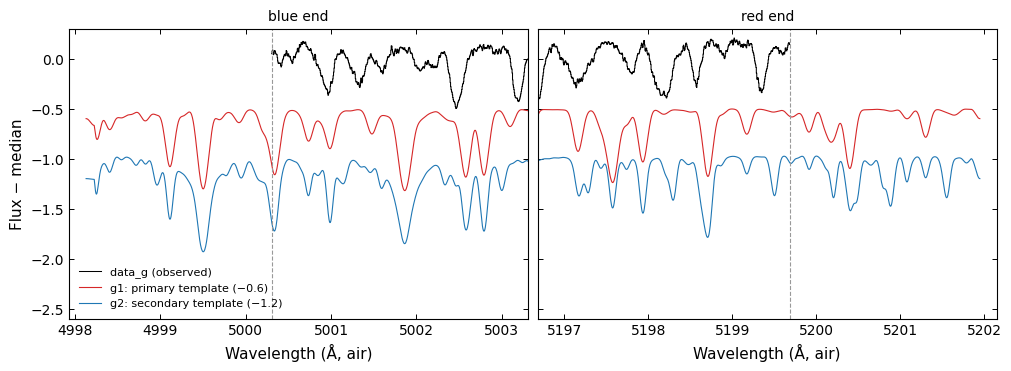

dv = 0.3000 km/s; 39073 of 39189 observed pixels kept; templates extended by 130.5 km/s (blue) and 130.5 km/s (red); V_MAX = 124.0 km/s


In [6]:
# Trial velocities to ±120 km/s every 2 km/s (step 4); the fine map (step 5) reaches 2 steps further
VEL_BOUND, DVEL = 120, 2.0                                # km/s
V_MAX = VEL_BOUND + 2 * DVEL                              # km/s, the largest shift the fit reads
# Step 2: prepare the window (observed pixels; templates extended by V_MAX on each side)
win = prepare_window(w_log, f_log, *primary[o], *secondary[o], v_max=V_MAX)
# The templates' extended grid (Å), for the plot: `extension` pixels on the left, and one
# more on the right when the window has an even number of pixels (odd total length)
w_ext = extend_log_grid(win.wave, win.extension + 1)[1:1 + win.g1.size]

# Both ends of the window: the data stop at its edges (dashed), the templates go on
# past each one by V_MAX, so a shift of either sign reads real template spectrum
fig, (ax_blue, ax_red) = plt.subplots(1, 2, sharey=True, figsize=(10, 3.6))
for ax, edge, xlim in ((ax_blue, win.wave[0], (w_ext[0] - 0.2, win.wave[0] + 3)),
                       (ax_red, win.wave[-1], (win.wave[-1] - 3, w_ext[-1] + 0.2))):
    plot_data(ax, win.wave, win.data_g, label="data_g (observed)")
    plot_model(ax, w_ext, win.g1 - 0.6, lw=0.8, label="g1: primary template (−0.6)")
    plot_extra(ax, w_ext, win.g2 - 1.2, lw=0.8, label="g2: secondary template (−1.2)")
    ax.axvline(edge, color=GREY, lw=0.8, ls="--")
    ax.set_xlim(*xlim)
    ax.set_xlabel("Wavelength (Å, air)")
ax_blue.set_ylim(-2.6, 0.3)
ax_blue.set_ylabel("Flux − median")
ax_blue.set_title("blue end", fontsize=10)
ax_red.set_title("red end", fontsize=10)
ax_blue.legend(loc="lower left", fontsize=8)
plt.show()
# How far the templates reach past each end (km/s)
left, right = C_KMS * np.log(win.wave[0] / w_ext[0]), C_KMS * np.log(w_ext[-1] / win.wave[-1])
print(f"dv = {win.dv:.4f} km/s; {win.wave.size} of {w_log.size} observed pixels kept; templates "
      f"extended by {left:.1f} km/s (blue) and {right:.1f} km/s (red); V_MAX = {V_MAX} km/s")

**Step 3: the noise model.** Neighbouring pixels of the fine grid share one native pixel's
noise. `window_stats` takes the `oversampling` (native step over grid step), so that the errors
count native pixels, and `noise_psd`, the noise power per Fourier mode left by the spline
resampling (`resampling_noise_psd`); then χ² per degree of freedom is ≈ 1 for honest noise
([correlation engines § noise](../../docs/correlation_engines.md#noise-oversampling-and-n_eff)).
`sigma=1.0` is a unit noise for now: step 6 measures the real one.

In [7]:
# Step 3: noise power per Fourier mode left by the spline resampling
psd = resampling_noise_psd(win.wave.size, native, win.dv, native_phases(wave, win.wave, win.dv))
# Noise-model keywords of window_stats; oversampling counts native pixels
noise_kw = dict(sigma=1.0, oversampling=max(1.0, native / win.dv), noise_psd=psd,
                velocity_convention="cz")
# Report the oversampling and the share of native noise power that survives
print(f"oversampling {noise_kw['oversampling']:.2f}; the spline keeps {psd.mean():.2f} of the "
      "native noise power")

oversampling 2.03; the spline keeps 0.87 of the native noise power


**Step 4: sufficient statistics on a (v1, v2) grid.** At every trial velocity `window_stats`
shifts each extended template by a Fourier phase factor and reads it on the observed pixels, so
the χ² is a sum over those pixels. A free offset per window (the continuum level) is projected
out, which centres every sum, as in a Pearson correlation. Six statistics remain, `SD`,
`S11(v1)`, `S22(v2)`, `b1(v1)`, `b2(v2)`, `A12(v1, v2)`
([correlation engines § model](../../docs/correlation_engines.md#model-and-sufficient-statistics)), with `nu`, the noise
degrees of freedom (the offset costs one). `S11` and `S22` vary with velocity as lines move into
and out of the window. The coarse grid (±120 km/s every 2 km/s) only has to *locate* the peak.
Steps 1-4 as one function, run on both orders:

In [8]:
# Step 4: coarse grid of trial velocities for both stars, ±120 km/s
v_grid = np.arange(-VEL_BOUND, VEL_BOUND + 0.5 * DVEL, DVEL)

# Steps 1-4 for one order: window, noise keywords and sufficient statistics
def prepare_order(wave, flux, template1, template2):
    '''Steps 1-4 for one order: its TodcorWindow, the window_stats keywords, its statistics.'''
    native = dv_from_wave(wave)
    win = prepare_window(*resample_to_log_grid(wave, flux, DV), *template1, *template2,
                         v_max=V_MAX)
    psd = resampling_noise_psd(win.wave.size, native, win.dv, native_phases(wave, win.wave, win.dv))
    kw = dict(sigma=1.0, oversampling=max(1.0, native / win.dv), noise_psd=psd,
              velocity_convention="cz")
    return win, kw, window_stats(win.data_g, win.g1, win.g2, win.dv, v_grid, v_grid, **kw)

# Prepare every order of epoch 0
windows = [prepare_order(records[k].wave[o], records[k].flux[o], primary[o], secondary[o])
           for o in range(len(records[k].wave))]
# Order 0 must reproduce the window built step by step above
assert np.array_equal(windows[0][0].data_g, win.data_g)  # order 0 as in steps 1-3
# The sufficient statistics of each order; S11 and S22 over the trial velocities
for o, (_, _, st) in enumerate(windows):
    print(f"order {o}: S11 = {st['S11'].min():.0f}-{st['S11'].max():.0f}, "
          f"S22 = {st['S22'].min():.0f}-{st['S22'].max():.0f}, SD = {st['SD']:.0f}, "
          f"nu = {st['nu']:.0f}; b1 {st['b1'].shape}, A12 {st['A12'].shape}")

order 0: S11 = 785-792, S22 = 986-990, SD = 495, nu = 16816; b1 (121,), A12 (121, 121)
order 1: S11 = 533-539, S22 = 671-679, SD = 335, nu = 15879; b1 (121,), A12 (121, 121)


**Step 5: the joint fit.** The two orders belong to one epoch, so they share
$(v_1, v_2, a_1, a_2)$ and their statistics add
([§ pooling orders](../../docs/correlation_engines.md#pooling-orders)). `joint_fit` pools them, profiles out the amplitudes,
re-evaluates every window on a fine grid around the coarse peak, and takes the velocities and
their Cramér-Rao errors from the curvature of the fine log-likelihood
([§ peak refinement and the errors](../../docs/correlation_engines.md#peak-refinement-and-the-errors)).

In [9]:
# Step 5: joint fit of the two orders at unit noise (pass 1)
prepared = [(win, kw) for win, kw, _ in windows]          # what joint_fit re-evaluates
stats = [st for _, _, st in windows]
fine_cache = {}                                           # fine-map statistics, kept for step 6
first = joint_fit(stats, None, prepared, v_grid, v_grid, nonneg=True, output="ccf",
                  fine_cache=fine_cache)
# Pass 1 yields the noise variance (chi2 per dof), not yet usable errors
print(f"pass 1, at unit noise: v1 = {first.best['v1']:.4f} km/s, v2 = {first.best['v2']:.4f} km/s, "
      f"chi2 per dof = {first.best['chi2_red']:.2e}")

pass 1, at unit noise: v1 = 36.8229 km/s, v2 = -34.7089 km/s, chi2 per dof = 4.01e-04


**Step 6: the noise, and the second pass.** Pass 1 assumed unit noise, so its χ² per degree of
freedom is the noise variance itself, $\sigma^2 \approx 4 \times 10^{-4}$, and its errors are
meaningless. `window_noise` reads each order's $\sigma_i$ from its share of the joint χ² at the
peak; pass 2 weights each order by $1/\sigma_i^2$, re-pooling the same statistics and cached
fine maps (`fine_cache`): no new Fourier transforms.

In [10]:
# Step 6: each order's noise from its share of the joint chi2 at the peak
noise, fallback = window_noise(first.window_chi2, [st["nu"] for st in first.at_peak])
# Pass 2: re-pool the same statistics, weighting each order by 1/sigma^2
fit = joint_fit(stats, 1.0 / noise**2, prepared, v_grid, v_grid, nonneg=True, output="ccf",
                fine_cache=fine_cache)

# Read the velocities (km/s), their Cramér-Rao errors and the amplitudes
crlb, best = fit.crlb, fit.best
rv1, rv2 = crlb["peak_refined"]
# Compare with the injected values
print(f"noise per order: {np.round(noise, 4)}  (injected 1/50 = 0.02)")
print(f"v1 = {rv1:8.4f} ± {crlb['sigma_v1']:.4f} km/s   (truth {v1_true[k]:8.4f})")
print(f"v2 = {rv2:8.4f} ± {crlb['sigma_v2']:.4f} km/s   (truth {v2_true[k]:8.4f})")
print(f"a1 = {best['a1']:.3f}, a2 = {best['a2']:.3f}   (truth 0.7, 0.3)")
print(f"reduced chi2 = {best['chi2_red']:.3f}, correlation of the v1 and v2 errors = {crlb['rho']:+.3f}")
# The noise is recovered and both RVs lie within 3 sigma of the truth
assert not fallback.any() and np.allclose(noise, 0.02, rtol=0.03)
assert abs(rv1 - v1_true[k]) < 3 * crlb["sigma_v1"] and abs(rv2 - v2_true[k]) < 3 * crlb["sigma_v2"]

noise per order: [0.0199 0.0201]  (injected 1/50 = 0.02)
v1 =  36.8229 ± 0.0039 km/s   (truth  36.8222)
v2 = -34.7088 ± 0.0074 km/s   (truth -34.7037)
a1 = 0.700, a2 = 0.300   (truth 0.7, 0.3)
reduced chi2 = 1.000, correlation of the v1 and v2 errors = +0.005


**What pooling buys.** Each order fitted alone (with the same noise weights) against the two
together. The orders' information adds, so the joint errors are close to the inverse-variance
combination of the single-order ones:

In [11]:
# Fit each order on its own, with the same noise weights
alone = [joint_fit([stats[o]], 1.0 / noise[o:o + 1]**2, [prepared[o]], v_grid, v_grid,
                   nonneg=True, output="ccf").crlb for o in range(2)]
# The joint error must equal the inverse-variance combination of the single-order errors
for name in ("sigma_v1", "sigma_v2"):
    single = np.array([c[name] for c in alone])
    combined = 1 / np.sqrt(np.sum(single**-2))
    print(f"{name}: order 0 alone {single[0] * 1e3:4.1f} m/s, order 1 alone {single[1] * 1e3:4.1f} m/s, "
          f"both {crlb[name] * 1e3:4.1f} m/s (inverse-variance sum {combined * 1e3:4.1f} m/s)")
    assert np.isclose(crlb[name], combined, rtol=0.02)

sigma_v1: order 0 alone  5.1 m/s, order 1 alone  6.3 m/s, both  3.9 m/s (inverse-variance sum  3.9 m/s)
sigma_v2: order 0 alone  8.7 m/s, order 1 alone 13.7 m/s, both  7.4 m/s (inverse-variance sum  7.4 m/s)


**The maps.** `fit.profile` holds the pooled coarse maps. The two-dimensional correlation
$R(v_1, v_2)$ is the fraction of the spectrum's line power that the best-fit pair of templates
explains, $R^2 = 1 - \chi^2_{\min} / S_D$, from 0 (white) to 1 (black). The profile
log-likelihood is $\ln L = -\chi^2_{\min}/2 = -\tfrac{1}{2} S_D\,(1 - R^2)$, so the two maps peak
at the same node.

The dark ridges of $R$, along constant $v_1$ and constant $v_2$, are where one template matches
one star; the primary's is darker (70% of the light). Only at the crossing do both match: the
fit (red +) sits on the truth (blue ×).

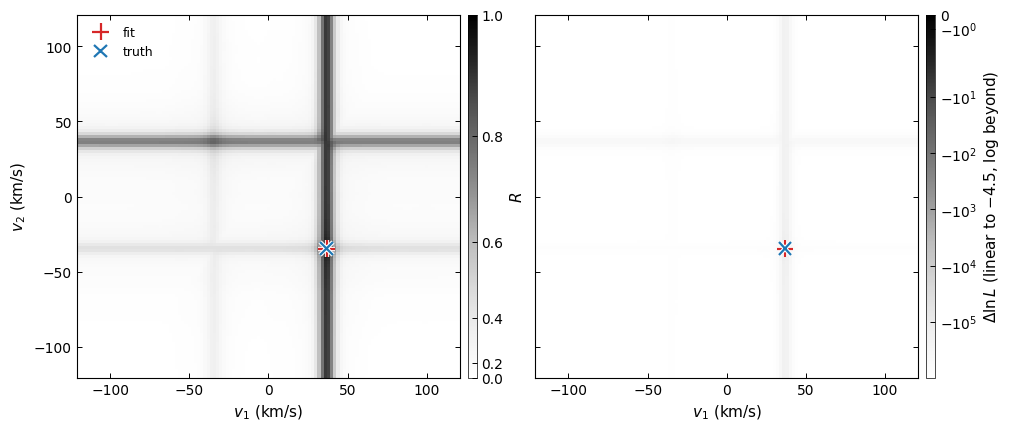

R at the fit = 0.9921; the lnL map is 9.9e+05 deep


In [12]:
# The pooled coarse maps: R and the profile log-likelihood
R, lnL = fit.profile["R"], fit.profile["logL_profile"]   # indexed [v1, v2]
# The two maps are one quantity, lnL = -S_D (1 - R^2) / 2, with the same peak node
assert np.allclose(lnL, -0.5 * fit.pooled["SD"] * (1 - R**2))
assert np.argmax(R) == np.argmax(lnL)

# R (left) and ΔlnL (right) over (v1, v2), with the fit and the truth marked
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, z, label, loglike in [(axs[0], R, "$R$", False),
                              (axs[1], lnL - lnL.max(), DLNL_LABEL, True)]:
    mesh = map_image(ax, v_grid, v_grid, z.T, loglike=loglike)     # transposed: v1 along x
    map_colorbar(mesh, label, ax=ax)
    mark_fit(ax, rv1, rv2, label="fit")
    mark_truth(ax, v1_true[k], v2_true[k], label="truth")
    ax.set_xlabel("$v_1$ (km/s)")
axs[0].set_ylabel("$v_2$ (km/s)")
axs[0].legend(loc="upper left")
plt.show()
print(f"R at the fit = {best['R']:.4f}; the lnL map is {np.ptp(lnL):.1e} deep")

$\ln L$ drops by ~$10^6$ across the map and by thousands one node (2 km/s) from the peak, while
the errors are a few m/s. So even on a logarithmic grey scale (linear to $\Delta\ln L = -4.5$,
the 3σ level for one parameter, −5.9 for (v1, v2) jointly) all but the peak node is white: $R$
is the map to *look at*. `output` only chooses which is `profile['map']`
([§ two maps, one peak](../../docs/correlation_engines.md#two-maps-one-peak)):

In [13]:
# Refit asking for the log-likelihood map as the primary output
fit_lnl = joint_fit(stats, 1.0 / noise**2, prepared, v_grid, v_grid, nonneg=True,
                    output="loglike", fine_cache=fine_cache)
# Only profile['map'] may differ; velocities, errors and amplitudes are identical
assert fit_lnl.crlb["peak_refined"] == crlb["peak_refined"] and fit_lnl.best == best
assert fit_lnl.crlb["sigma_v1"] == crlb["sigma_v1"] and fit_lnl.crlb["sigma_v2"] == crlb["sigma_v2"]
assert np.array_equal(fit_lnl.profile["map"], lnL) and np.array_equal(fit.profile["map"], R)
print("output='loglike': the same velocities, errors and amplitudes; only profile['map'] changes")

output='loglike': the same velocities, errors and amplitudes; only profile['map'] changes


**Step 7: look at the residual.** `model_flux` rebuilds the composite with the fit's own
model: the extended templates shifted to the fitted velocities, scaled by the fitted amplitudes,
on the window's pixels. The window's fitted offset is the mean of data minus model. The residual
should match the injected noise, σ = 0.02 per native pixel, or a little less, as resampling
smooths the noise (notebook 02). Nothing is tapered, so the whole window counts:

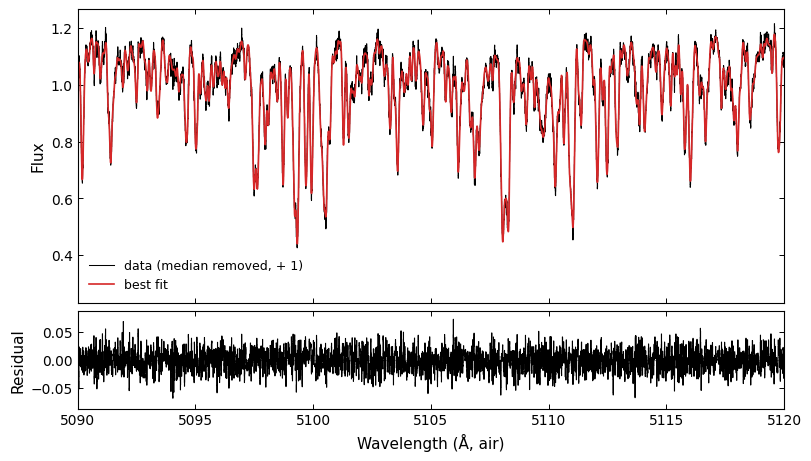

residual rms (whole window) = 0.0186


In [14]:
# Step 7: rebuild the composite from the fitted values (model_flux)
win = windows[0][0]                                       # order 0
model = model_flux(win.g1, win.g2, win.wave.size, win.dv, rv1, rv2, best["a1"], best["a2"])
# Add the fitted offset (the mean residual), then put data and model back on the flux scale
model = model + np.mean(win.data_g - model) + 1.0
data = win.data_g + 1.0
rms = np.std(data - model)

# Data and best fit (top), and their residual (bottom)
fig, axs = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, gridspec_kw={"height_ratios": (3, 1)})
plot_data(axs[0], win.wave, data, label="data (median removed, + 1)")
plot_model(axs[0], win.wave, model, label="best fit")
axs[0].set_ylabel("Flux")
axs[0].legend(loc="lower left")
axs[1].axhline(0, color=GREY, lw=0.8)
plot_data(axs[1], win.wave, data - model)
axs[1].set_ylabel("Residual")
axs[1].set_xlabel("Wavelength (Å, air)")
axs[1].set_xlim(5090, 5120)
plt.show()
print(f"residual rms (whole window) = {rms:.4f}")
# The residual matches the injected noise, or is a little smaller
assert 0.015 < rms < 0.02

## 4. The whole orbit

Steps 1-6 as one function: prepare every order, fit at unit noise, estimate each order's noise,
fit again. Epochs are never pooled (the velocities change between them), so each gets its own
fit. This function is, call for call, what `CCF2d.cross_correlate` does (the last cell checks it);
its `amplitudes` switch is section 5's.

In [15]:
# Steps 1-6 for one epoch: prepare every order, fit twice (unit noise, then weighted)
def todcor_fit(waves, fluxes, templates1, templates2, amplitudes="shared"):
    '''One epoch: steps 1-4 for every order, then the two-pass joint fit (steps 5-6).'''
    windows = [prepare_order(w, f, t1, t2)
               for w, f, t1, t2 in zip(waves, fluxes, templates1, templates2)]
    prepared, stats = [(win, kw) for win, kw, _ in windows], [st for _, _, st in windows]
    cache = {}
    first = joint_fit(stats, None, prepared, v_grid, v_grid, nonneg=True, output="ccf",
                      amplitudes=amplitudes, fine_cache=cache)
    noise, _ = window_noise(first.window_chi2, [st["nu"] for st in first.at_peak],
                            amplitudes=amplitudes)
    return joint_fit(stats, 1.0 / noise**2, prepared, v_grid, v_grid, nonneg=True,
                     output="ccf", amplitudes=amplitudes, fine_cache=cache)

# Fit every epoch; epochs are never pooled
fits = [todcor_fit(rec.wave, rec.flux, primary, secondary) for rec in records]
# Collect each star's velocities (km/s), errors and amplitudes
vels1, vels2 = np.array([f.crlb["peak_refined"] for f in fits]).T
evels1, evels2 = np.array([(f.crlb["sigma_v1"], f.crlb["sigma_v2"]) for f in fits]).T
amps1, amps2 = np.array([(f.best["a1"], f.best["a2"]) for f in fits]).T
assert (vels1[0], vels2[0]) == (rv1, rv2)                 # epoch 0 as in section 3

# The O-C scatter must match the formal error: the errors are honest
for name, vel, err, true in [("primary", vels1, evels1, v1_true),
                             ("secondary", vels2, evels2, v2_true)]:
    rms = np.std(vel - true)
    print(f"{name:9s}: rms(O-C) = {rms * 1e3:5.1f} m/s, median error = {np.median(err) * 1e3:5.1f} m/s")
    assert 0.5 < rms / np.median(err) < 1.5
# Fitted amplitudes over the orbit (injected 0.7 and 0.3)
print(f"amplitudes: a1 = {amps1.mean():.3f} ± {amps1.std():.3f}, a2 = {amps2.mean():.3f} ± {amps2.std():.3f}")

primary  : rms(O-C) =   3.5 m/s, median error =   3.9 m/s
secondary: rms(O-C) =   6.5 m/s, median error =   7.4 m/s
amplitudes: a1 = 0.700 ± 0.001, a2 = 0.300 ± 0.000


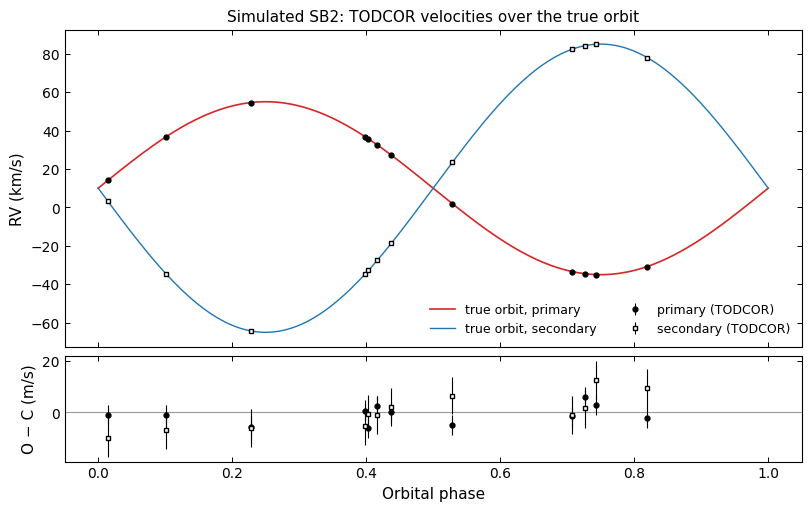

In [16]:
# RVs over the true orbit (top), and O-C with the formal errors (bottom)
phase = (times % P) / P
grid = np.linspace(0, 1, 300)
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": (3, 1)})
plot_model(axs[0], grid, gamma + K1 * np.sin(2 * np.pi * grid), label="true orbit, primary")
plot_extra(axs[0], grid, gamma - K2 * np.sin(2 * np.pi * grid), label="true orbit, secondary")
plot_points(axs[0], phase, vels1, evels1, label="primary (TODCOR)")
plot_points(axs[0], phase, vels2, evels2, fmt="s", mfc="white", label="secondary (TODCOR)")
axs[0].set_ylabel("RV (km/s)")
axs[0].set_title("Simulated SB2: TODCOR velocities over the true orbit")
axs[0].legend(ncols=2, loc="lower right")
axs[1].axhline(0, color=GREY, lw=0.8)
plot_points(axs[1], phase, (vels1 - v1_true) * 1e3, evels1 * 1e3)
plot_points(axs[1], phase, (vels2 - v2_true) * 1e3, evels2 * 1e3, fmt="s", mfc="white")
axs[1].set_xlabel("Orbital phase")
axs[1].set_ylabel("O − C (m/s)")
plt.show()

## 5. No edge bias; one light ratio per order

Earlier versions shifted each template circularly *within* the window (a line pushed past one
end came back at the other), hid the ends with a taper that moved with the shifted template, and
read the narrow peak with a quadratic patch. On short, line-crowded windows that biased the
velocities by several m/s (in this test, with the old taper settings: 15.6 m/s on 50 Å, 3.1 m/s on 200 Å). Now the
templates extend past the window (step 2), nothing is tapered, and a degree-6 polynomial reads
the fine map's peak
([§ peak refinement and the errors](../../docs/correlation_engines.md#peak-refinement-and-the-errors)).
A noiseless test at two epochs, so any offset is bias:

In [17]:
# Noiseless test at two epochs, so any offset from the truth is bias
rv_test = np.array([[30.0, -45.0], [-42.3, 51.7]])
# A short and a long window of the same two stars
for window in [(5000, 5050), (5000, 5200)]:
    # Simulate noiseless epochs in this window, and the matched templates
    test = Simulation(like="HARPS", windows_A=[window], times=[0.0, 1.0], rv_kms=rv_test,
                      components=stars)
    test_records, _ = simulate(test)
    s1, s2 = component_spectra(test)
    # Fit each epoch
    out = [todcor_fit(rec.wave, rec.flux, s1, s2) for rec in test_records]
    # Velocity bias against the truth (km/s), and the fitted amplitudes
    bias = np.max(np.abs(np.array([f.crlb["peak_refined"] for f in out]) - rv_test))
    amps = np.array([(f.best["a1"], f.best["a2"]) for f in out])
    print(f"{window[1] - window[0]} Å window: largest velocity bias {bias * 1e3:.3f} m/s, "
          f"amplitudes {amps[:, 0].mean():.4f}, {amps[:, 1].mean():.4f}")
    # Both windows: below 0.05 m/s
    assert bias < 5e-5

50 Å window: largest velocity bias 0.015 m/s, amplitudes 0.7000, 0.3000


200 Å window: largest velocity bias 0.005 m/s, amplitudes 0.7000, 0.3000


The ~0.01 m/s left comes from resampling the spectra onto the grid. The amplitudes are
exact as well: the free offset takes up the continuum level.

**One light ratio per order.** Two stars of different temperature have a light ratio that
changes across the spectrum. `amplitudes='per_order'` gives each order its own $(a_1, a_2)$ and
shares only the velocities
([§ pooling orders](../../docs/correlation_engines.md#pooling-orders)). A noiseless test: the
same two stars at 75 : 25 in one order and at 60 : 40 in another:

In [18]:
# Two noiseless orders whose light ratios differ: 75:25 at 5000 Å, 60:40 at 5300 Å
pieces = []
for window, (a1, a2) in [((5000, 5050), (0.75, 0.25)), ((5300, 5350), (0.60, 0.40))]:
    pair = [dict(stars[0], amplitude=a1), dict(stars[1], amplitude=a2)]
    test = Simulation(like="HARPS", windows_A=[window], times=[0.0, 1.0], rv_kms=rv_test,
                      components=pair)
    test_records, _ = simulate(test)
    s1, s2 = component_spectra(test)
    pieces.append((test_records, s1[0], s2[0]))
# Each epoch's two orders, and the matched templates of each order
epochs = [([recs[e].wave[0] for recs, _, _ in pieces], [recs[e].flux[0] for recs, _, _ in pieces])
          for e in range(len(rv_test))]
t1s, t2s = [t1 for _, t1, _ in pieces], [t2 for _, _, t2 in pieces]

# Fit with one amplitude pair for both orders, then with one pair per order
largest = {}
for amplitudes in ("shared", "per_order"):
    out = [todcor_fit(waves, fluxes, t1s, t2s, amplitudes=amplitudes) for waves, fluxes in epochs]
    largest[amplitudes] = np.max(np.abs(np.array([f.crlb["peak_refined"] for f in out]) - rv_test))
    print(f"amplitudes={amplitudes!r:12}: largest velocity bias {largest[amplitudes] * 1e3:6.3f} m/s; "
          f"a1 = {np.round(out[0].best['a1'], 3)}, a2 = {np.round(out[0].best['a2'], 3)}")
# One shared pair misfits both orders and pulls the velocities; per-order amplitudes do not
assert largest["shared"] > 1e-3 and largest["per_order"] < 5e-5

amplitudes='shared'    : largest velocity bias 12.127 m/s; a1 = 0.704, a2 = 0.297


amplitudes='per_order' : largest velocity bias  0.010 m/s; a1 = [0.75 0.6 ], a2 = [0.25 0.4 ]


One shared pair cannot fit both orders, and the misfit pulls the velocities; per-order
amplitudes fit each order exactly. With a constant light ratio, as in sections 1-4, `'shared'`
is tighter: per-order costs two free parameters per order. All TODCOR caveats:
[limitations § TODCOR](../../docs/limitations.md#todcor).

## 6. The same numbers with the objects

`CCF2d.cross_correlate` (one epoch) and `Observations.calc_rv_against_two_templates` (every
epoch) call the same atoms in the same order on the same arrays, so they give the same numbers
to the last bit (`np.array_equal`, not a tolerance). `CCF2d` extends the templates by the
largest trial velocity plus its fine map's reach, `refine_span` coarse steps: our `V_MAX`. The
how-to [`howto/02_double_lined_binary`](../howto/02_double_lined_binary.ipynb) uses them
directly.

In [19]:
# The object interface to the same fit
from sparta import CCF2d, Observations
from sparta.instruments.simulated import component_templates

# The same two stars as Template objects
template1, template2 = component_templates(sim)          # primary and secondary as Templates
# The same settings as the atoms used; CCF2d's template extension is our V_MAX
settings = dict(dv=DV, vel_bound=VEL_BOUND, dvel=DVEL)
assert VEL_BOUND + CCF2d().refine_span * DVEL == V_MAX
# Fit every epoch with Observations.calc_rv_against_two_templates
obs = Observations(survey="SIMULATED", simulation=sim)
obs.calc_rv_against_two_templates(template1, template2, **settings)
# The objects must give the same numbers as the atoms, bit for bit
for objects, atoms in [(obs.vels1, vels1), (obs.vels2, vels2), (obs.evels1, evels1),
                       (obs.evels2, evels2), (obs.amps1, amps1), (obs.amps2, amps2)]:
    assert np.array_equal(objects, atoms)

# One epoch through CCF2d: its R map and noise must match as well
epoch0 = CCF2d().cross_correlate(obs.spec_list[0], template1, template2, **settings).Corr2d
assert np.array_equal(epoch0["R"], R) and np.array_equal(epoch0["sigma"], noise)
print("Observations and CCF2d: velocities, errors, amplitudes, the R map and the noise are "
      "identical to the atoms'")

Observations and CCF2d: velocities, errors, amplitudes, the R map and the noise are identical to the atoms'


## Summary / next

- A one-template CCF is biased on a blended double-lined spectrum; TODCOR fits both stars.
- A TODCOR fit is a chain of atoms: per order `resample_to_log_grid` → `prepare_window` →
  `resampling_noise_psd` → `window_stats`; then `joint_fit` at unit noise → `window_noise` →
  `joint_fit` weighted by the noise. Orders of one epoch add; epochs are fitted one by one.
- The templates extend past each window and each window has a free offset: no taper, no
  continuum setting, and no edge bias (~0.01 m/s on 50 Å). `amplitudes='per_order'` gives each
  order its own light ratio.

The derivation: [todcor_method.md](../../packages/todcor/docs/todcor_method.md) and the deep
dives in [`howto/todcor_detailed/`](../howto/todcor_detailed/).

**Next:** [`05_tiravel`](05_tiravel.ipynb): building the template from the observations.